# Pretrained time-series models vs the chart CNN — 5-minute US equities

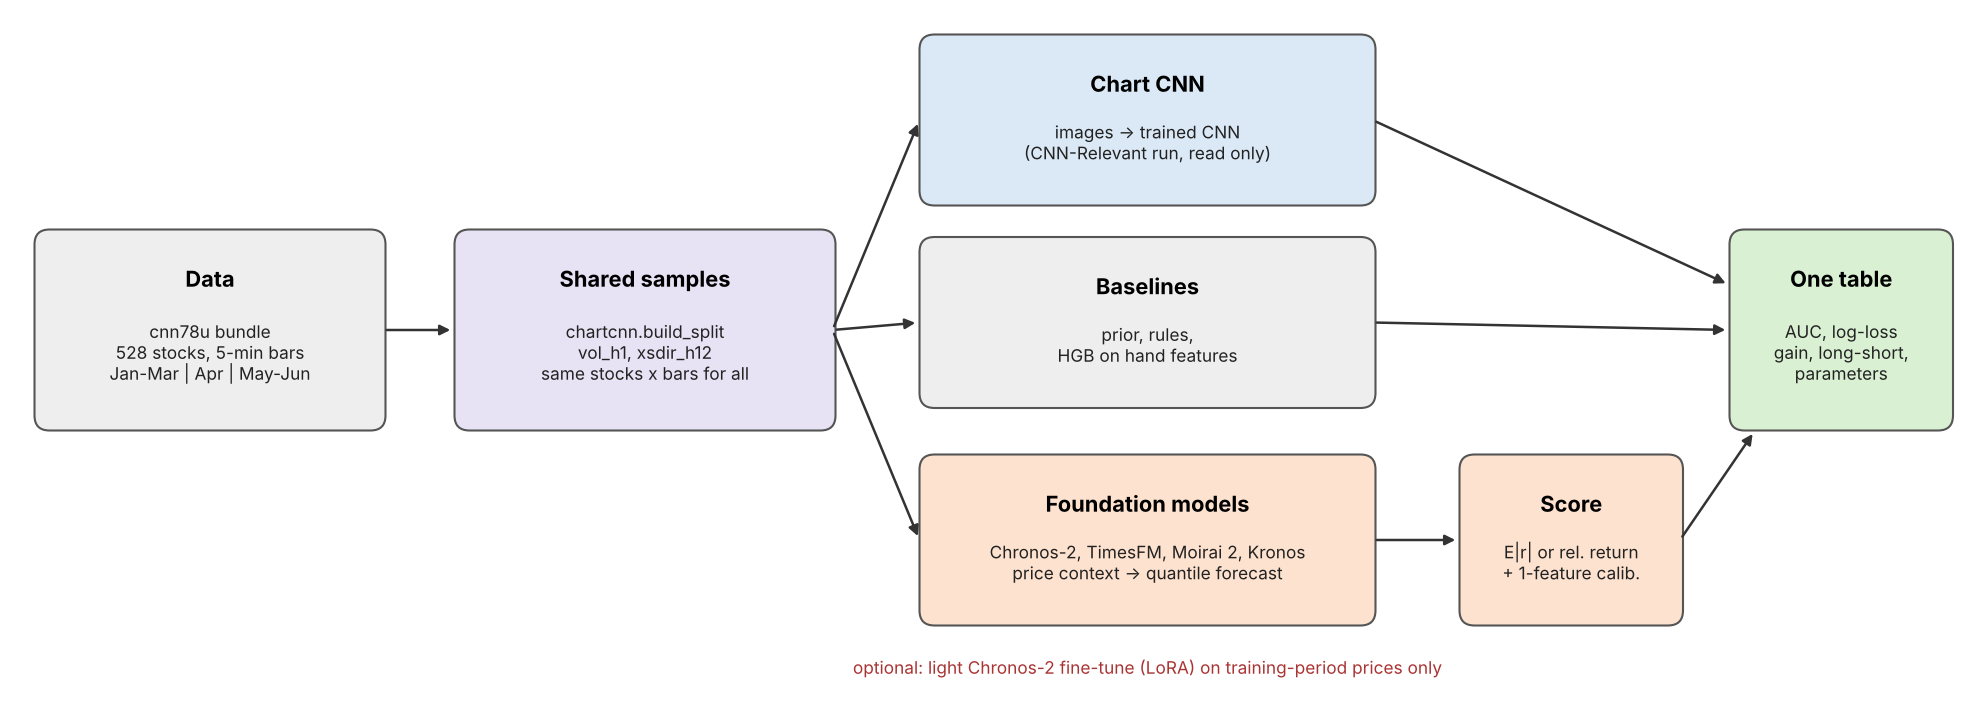

- **Question**: do off-the-shelf forecasting foundation models (Chronos-2, TimesFM, Moirai 2, Kronos) predict our two targets better than the chart CNN or simple baselines?
- **Same data, splits and labels** as `CNN-Relevant/ChartCNN_Baseline.ipynb` (shared `chartcnn` package): January–March train, April validation; `vol_h1` (next bar moves more than usual) and `xsdir_h12` (beats the cross-section over the next hour).
- **Zero-shot**: each model sees the last 78 closes and forecasts 12 bars ahead as quantiles. Its score is the forecast |return| (`vol`) or forecast return relative to other stocks (`xs_dir`). Labels are only used to fit a 1-feature calibration on training-period data, so log loss can be compared.
- **Light fine-tune (optional)**: Chronos-2 with LoRA on training-period price series. It learns to forecast prices; it never sees the labels.
- **Code**: all logic lives in `tsfm_compare/` next to this notebook. Cells only configure, run and display.

## 1. Install
Restart is **not** needed on a fresh runtime (if `peft` was already imported in this session, use Runtime > Restart session once after this cell). Moirai's package pins old library versions, so it is installed without dependencies.

In [ ]:
import os
LOCAL_TEST = os.environ.get("PMC_LOCAL_TEST") == "1"          # repository QA only
if not LOCAL_TEST:
    !pip -q install "chronos-forecasting>=2.2" "timesfm[torch]>=3.0" peft
    !pip -q install --no-deps "uni2ts==2.0.0"
    !pip -q install einops jaxtyping lightning gluonts hydra-core python-dotenv
    # Colab ships torchao 0.10, which recent peft (LoRA) refuses to import. We don't use torchao, so remove it.
    !pip -q uninstall -y torchao
    !git clone -q --depth 1 https://github.com/shiyu-coder/Kronos /content/Kronos 2>/dev/null || echo "Kronos already cloned"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
uni2ts 2.0.0 requires datasets~=2.17.1, but you have datasets 4.8.5 which is incompatible.
uni2ts 2.0.0 requires einops==0.7.*, but you have einops 0.8.2 which is incompatible.
uni2ts 2.0.0 requires gluonts~=0.14.3, but you have gluonts 0.17.0 which is incompatible.
uni2ts 2.0.0 requires hydra-core==1.3, but you have hydra-core 1.3.8 which is incompatible.
uni2ts 2.0.0 requires jaxtyping~=0.2.24, but you have jaxtyping 0.3.11 which is incompatible.
uni2ts 2.0.0 requires numpy~=1.26.0, but you have numpy 2.4.6 which is incompatible.
uni2ts 2.0.0 requires python-dotenv==1.0.0, but you have python-dotenv 1.2.4 which is incompatible.
uni2ts 2.0.0 requires scipy~=1.11.3, but you have sc

## 2. Setup
Mounts Drive, finds the shared `chartcnn` package and the data bundle, and copies the data to the Colab disk.

Mounted at /content/drive
chartcnn 2026-11-13.4 loaded from /content/drive/MyDrive/Colab Notebooks/EC/Project/Demo/CNN-Relevant/chartcnn/__init__.py
chartcnn from: /content/drive/MyDrive/Colab Notebooks/EC/Project/Demo/CNN-Relevant | data: /content/pmc_afq9dl10/bundle/prepared | device: cuda


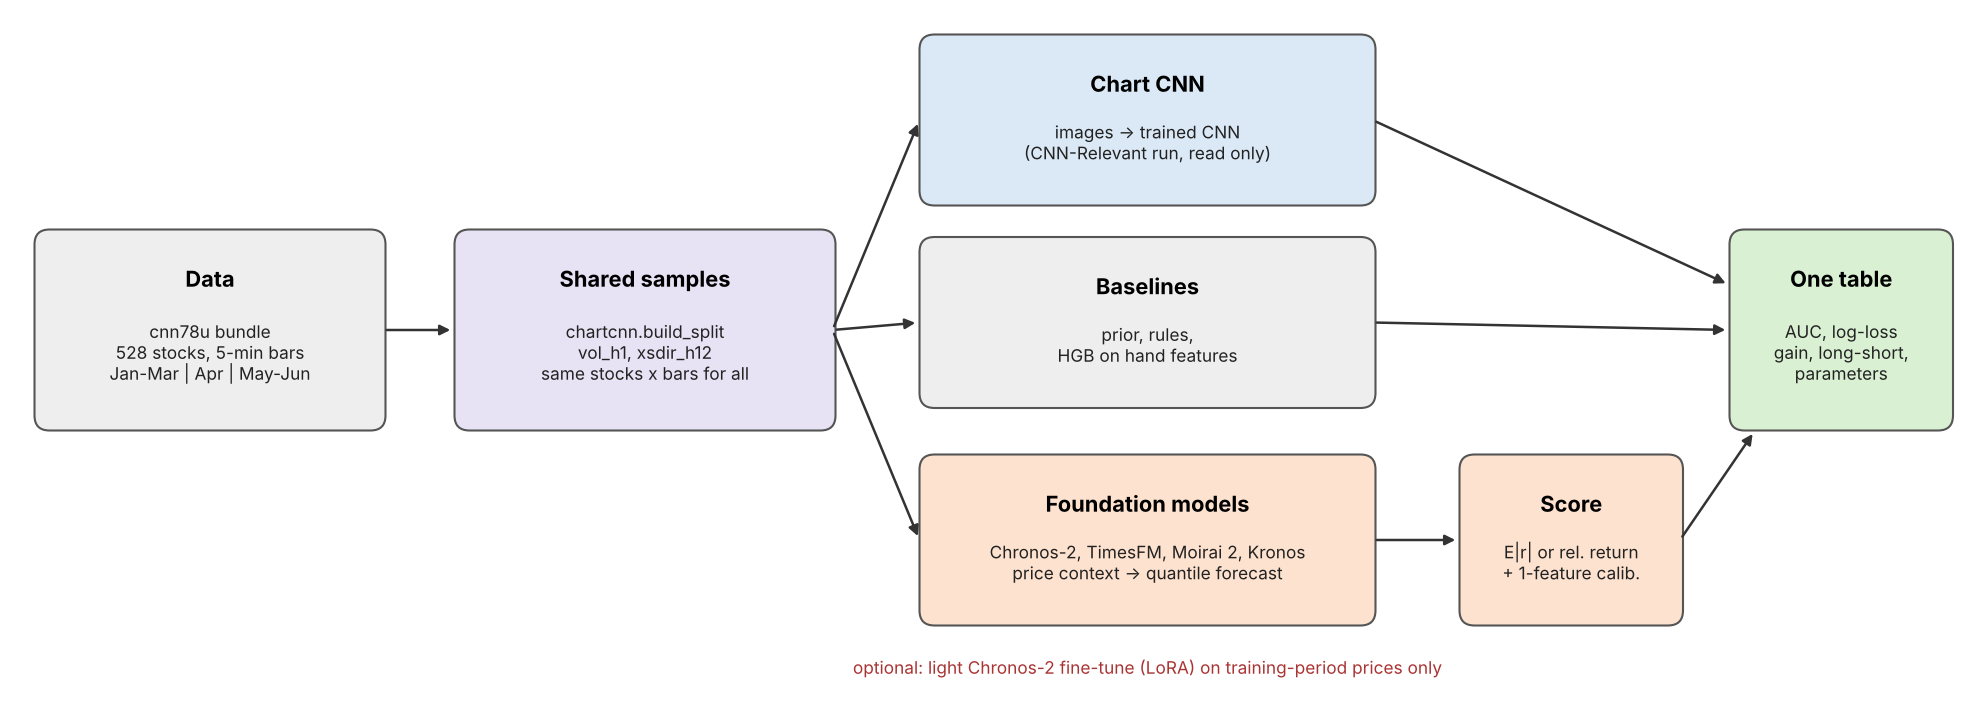

In [ ]:
import sys, shutil, tempfile, json
from pathlib import Path
from datetime import datetime, timezone

if LOCAL_TEST:
    DEMO = Path(os.environ["PMC_LOCAL_DEMO"])
else:
    from google.colab import drive
    drive.mount("/content/drive")
    DEMO = Path("/content/drive/MyDrive/Colab Notebooks/EC/Project/Demo")
HERE = DEMO / "Pretrained Model Comparison"                    # this notebook + tsfm_compare/
CNN_HOME = next(p for p in (DEMO / "CNN-Relevant", DEMO) if (p / "chartcnn").is_dir())
sys.path[:0] = [str(HERE), str(CNN_HOME)]

import numpy as np, pandas as pd, torch
from IPython.display import display
import chartcnn
from chartcnn.utils import stage_bundle, save_json, seed_all
from tsfm_compare import build_samples, union_keys, training_series, forecasters, runner, scoring, plots

LOCAL = Path(tempfile.mkdtemp(prefix="pmc_", dir=None if LOCAL_TEST else "/content"))
PREPARED = stage_bundle(DEMO, LOCAL / "bundle")                  # DEMO/cnn78u_colab_bundle.zip -> local disk
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("chartcnn from:", CNN_HOME, "| data:", PREPARED, "| device:", DEVICE)
from IPython.display import Image
if (HERE / "assets" / "flow.png").exists():
    display(Image(filename=str(HERE / "assets" / "flow.png"), width=900))   # same diagram as the top cell

## 3. Configuration
Change settings here only. Validation is a random set of whole decision bars (all stocks at that bar), identical for every model; 80 bars ≈ 35k samples per target.

In [ ]:
SMOKE = LOCAL_TEST                                              # tiny code check; never a result
assert DEVICE == "cuda" or SMOKE, "Select a GPU runtime (Runtime > Change runtime type)"

EXPERIMENTS = [
    dict(name="vol_h1", target="vol", horizon=1),               # volatility: signal known to exist
    dict(name="xsdir_h12", target="xs_dir", horizon=12),        # 1-hour relative direction
]
CONTEXT = 78            # bars the models see = exactly the CNN's chart window (one trading day)
HORIZON = 12            # forecast once to 12 bars ahead, used by both targets
STRIDE = 6              # same thinning as the CNN run
N_VALID_TIMES = 2 if SMOKE else 80
N_CALIB_TIMES = 2 if SMOKE else 40                              # training bars used for calibration only
SEED = 69

MODELS = [   # kind, Hugging Face id, inference batch size; add or remove freely
    dict(kind="chronos", name="chronos2", model_id="amazon/chronos-2", batch_size=1024),
    dict(kind="chronos", name="chronos_bolt_base", model_id="amazon/chronos-bolt-base", batch_size=1024),
    dict(kind="timesfm", name="timesfm", model_id="google/timesfm-3.0-pytorch", batch_size=512),
    dict(kind="moirai", name="moirai2_small", model_id="Salesforce/moirai-2.0-R-small", batch_size=1024),
    dict(kind="kronos", name="kronos_small", model_id="NeoQuasar/Kronos-small",
         tokenizer="NeoQuasar/Kronos-Tokenizer-base", repo="/content/Kronos", samples=8, batch_size=256),
]
FINETUNE = dict(enabled=True, base="amazon/chronos-2", mode="lora", learning_rate=1e-5,
                num_steps=3 if SMOKE else 2000, batch_size=8 if SMOKE else 256)

# Trained CNN to compare against: newest CNN-Relevant run with saved validation probabilities (or set a path / None).
runs = sorted((DEMO / "CNN-Relevant" / "runs").glob("*/settings.json"), key=lambda p: p.stat().st_mtime)
CNN_RUN = runs[-1].parent if runs else None

if SMOKE:
    MODELS = json.loads(os.environ["PMC_TEST_MODELS"])
    FINETUNE["base"] = MODELS[0]["model_id"]
RESUME_RUN_ID = None    # after a disconnect: put the old RUN_ID here to reuse its finished forecasts
RUN_ID = RESUME_RUN_ID or ("local_smoke" if SMOKE else datetime.now(timezone.utc).strftime("run_%Y%m%d_%H%M%S"))
RUN_DRIVE, RUN_LOCAL = HERE / "runs" / RUN_ID, LOCAL / "run"
if RESUME_RUN_ID:
    shutil.copytree(RUN_DRIVE, RUN_LOCAL, dirs_exist_ok=True)
RUN_DRIVE.mkdir(parents=True, exist_ok=True); RUN_LOCAL.mkdir(parents=True, exist_ok=True)
save_json(RUN_LOCAL / "settings.json", dict(experiments=EXPERIMENTS, context=CONTEXT, horizon=HORIZON, stride=STRIDE,
          n_valid_times=N_VALID_TIMES, n_calib_times=N_CALIB_TIMES, models=MODELS, finetune=FINETUNE,
          cnn_run=str(CNN_RUN)), RUN_DRIVE)
print("CNN run:", CNN_RUN, "\nresults ->", RUN_DRIVE)

CNN run: /content/drive/MyDrive/Colab Notebooks/EC/Project/Demo/CNN-Relevant/runs/run_20261113_185632 
results -> /content/drive/MyDrive/Colab Notebooks/EC/Project/Demo/Pretrained Model Comparison/runs/run_20261114_012926


## 4. Samples
Same labels as the CNN notebook. Each (stock, bar) pair is forecast once and shared by both targets.

In [ ]:
seed_all(SEED)
store = chartcnn.Store(PREPARED)
SAMPLES = build_samples(store, EXPERIMENTS, STRIDE, N_VALID_TIMES, N_CALIB_TIMES, SEED)
KEYS = {part: union_keys(SAMPLES, part) for part in ("valid", "calib")}
display(pd.DataFrame({name: {f"{part} samples": len(d[part]) for part in ("train", "calib", "valid")}
                      | {"valid positive share": round(d["valid"].label.mean(), 3)}
                      for name, d in SAMPLES.items()}))
print({part: f"{len(k):,} series to forecast" for part, k in KEYS.items()})

,vol_h1,xsdir_h12
train samples,287689.000,283835.0
calib samples,14564.000,14385.0
valid samples,27385.000,26979.0
valid positive share,0.395,0.5


{'valid': '27,389 series to forecast', 'calib': '14,580 series to forecast'}


## 5. Zero-shot foundation models
For each model: load (prints the **total parameter count**), forecast validation and calibration series, score both targets. Forecasts are cached in `runs/<RUN_ID>/forecasts/` on Drive; after a disconnect set `RESUME_RUN_ID` in section 3 and run all again, and finished models are not re-forecast. A model that fails to install or load is reported and skipped.

In [ ]:
ROWS, PROBS, FORECASTS = {}, {}, {}

def record(result, kind):
    rows, probs = scoring.evaluate_forecaster(result["name"], result["n_params"], result["q"]["valid"], result["q"]["calib"],
                                              KEYS["valid"], KEYS["calib"], SAMPLES, EXPERIMENTS, kind, result["seconds"])
    for exp, row in rows.items():
        ROWS.setdefault(exp, []).append(row)
        PROBS[(exp, result["name"])] = probs[exp]
    FORECASTS[result["name"]] = result["q"]["valid"]
    display(pd.DataFrame(rows).T[["parameters", "roc_auc", "log_loss_gain_vs_prior_pct", "mae_vs_random_walk"]])

for spec in MODELS:
    print("\n" + "=" * 20, spec.get("name", spec["kind"]), "=" * 20)
    try:
        result = runner.run_model(spec, store, PREPARED, KEYS, CONTEXT, HORIZON, DEVICE,
                                  RUN_LOCAL / "forecasts", RUN_DRIVE / "forecasts")
    except Exception as err:
        print(f"SKIPPED {spec['model_id']}: {type(err).__name__}: {err}")
        continue
    record(result, "foundation (zero-shot)")
    result["model"].unload()


==================== chronos2 ====================


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  478MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

... (26 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.0MB            

model.safetensors: downloading bytes:           |  0.00B            

kronos_small [NeoQuasar/Kronos-small]: 28,699,418 parameters (loaded in 6s)
  kronos_small: 5,120/27,389 series, 12/s
  kronos_small: 10,240/27,389 series, 12/s
  kronos_small: 15,360/27,389 series, 12/s
  kronos_small: 20,480/27,389 series, 12/s
  kronos_small: 25,600/27,389 series, 12/s
  kronos_small: 27,389/27,389 series, 12/s
  kronos_small valid: 27,389 forecasts in 2375s
  kronos_small: 5,120/14,580 series, 12/s
  kronos_small: 10,240/14,580 series, 12/s
  kronos_small: 14,580/14,580 series, 12/s
  kronos_small calib: 14,580 forecasts in 1264s


,parameters,roc_auc,log_loss_gain_vs_prior_pct,mae_vs_random_walk
vol_h1,28699418,0.699058,11.066379,1.05418
xsdir_h12,28699418,0.479912,-0.156348,1.053156


Visual check: context (black), forecast median and 10–90% band, realised path (green) for a few validation series.

chronos2


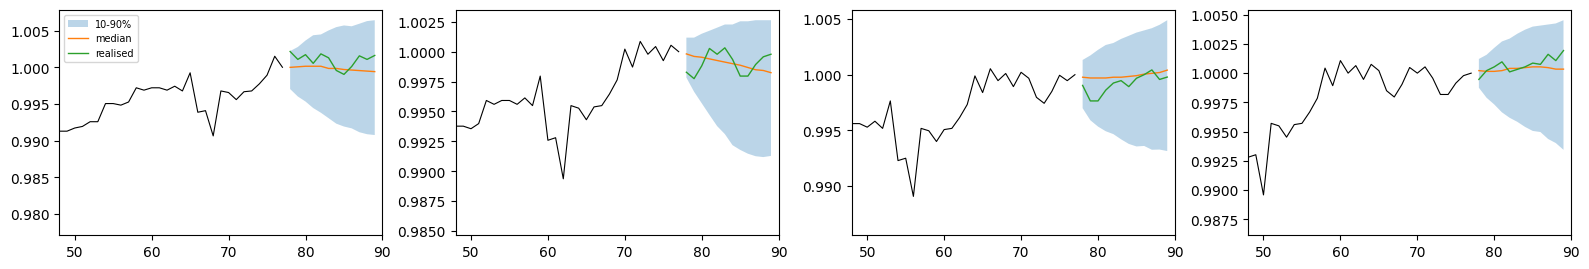

chronos_bolt_base


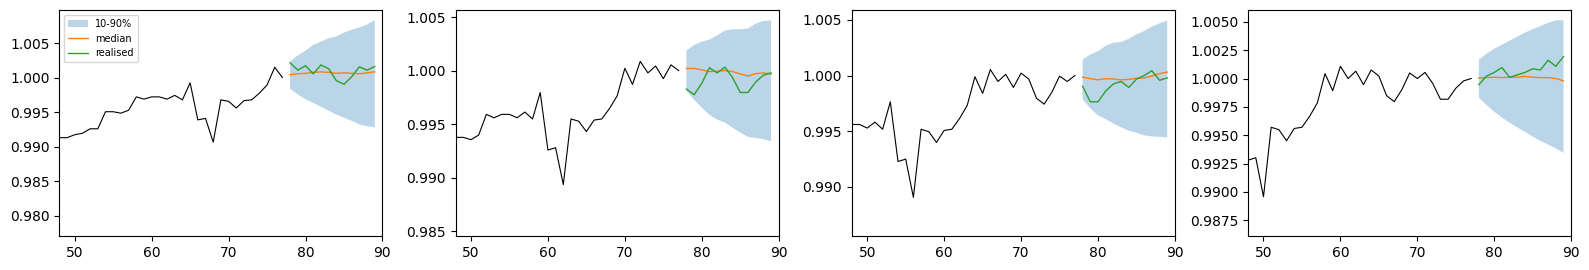

timesfm


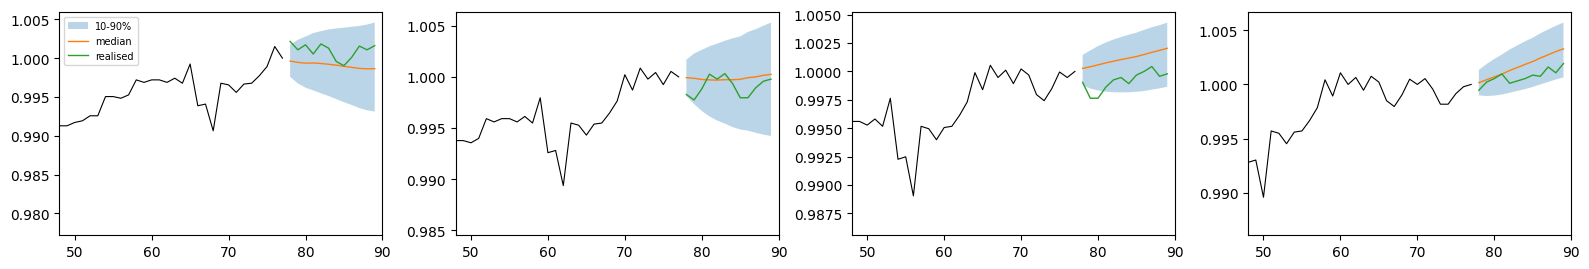

moirai2_small


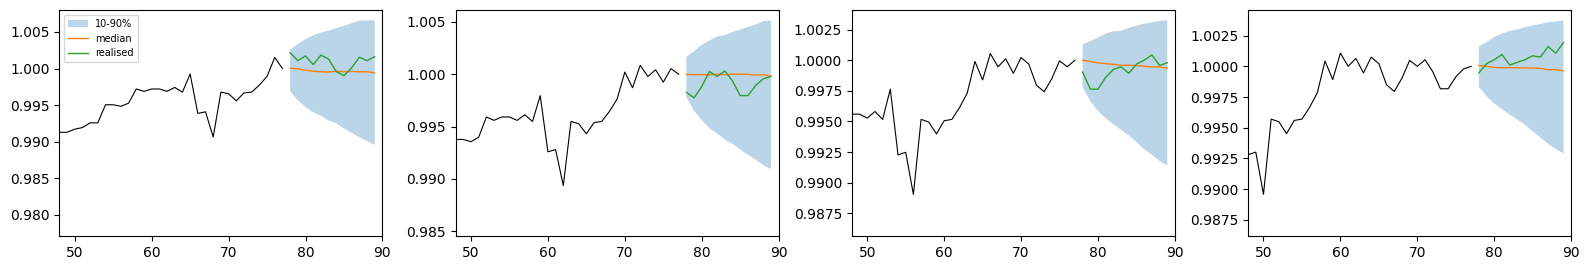

kronos_small


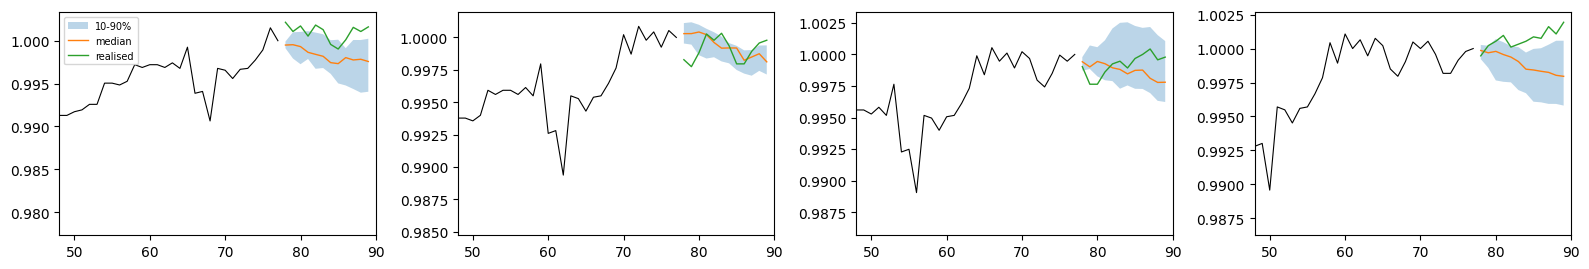

In [ ]:
from tsfm_compare.samples import close_contexts
ctx = close_contexts(store, KEYS["valid"].head(4), CONTEXT)
fut = KEYS["valid"].head(4)
realised = store.close[fut.security_index.to_numpy()[:, None], fut.end_index.to_numpy()[:, None] + np.arange(1, HORIZON + 1)]
realised = realised / store.close[fut.security_index.to_numpy(), fut.end_index.to_numpy()][:, None]
for name, q in FORECASTS.items():
    print(name); plots.plot_forecast_examples(q[:4], ctx, realised)

## 6. Light fine-tune: Chronos-2 + LoRA (optional)
Trains on the January–March price series of every stock (forecast loss, no labels, nothing after the training end date), then is scored exactly like the zero-shot models.

In [ ]:
cached = all((RUN_LOCAL / "forecasts" / f"chronos2_ft_{part}.npy").exists() for part in ("valid", "calib"))
if FINETUNE["enabled"] and cached:          # resumed run: reuse the fine-tuned forecasts, skip training
    meta = RUN_LOCAL / "forecasts" / "chronos2_ft_params.json"
    n_params = json.loads(meta.read_text())["parameters"] if meta.exists() else None
    q = {part: np.load(RUN_LOCAL / "forecasts" / f"chronos2_ft_{part}.npy") for part in ("valid", "calib")}
    print(f"chronos2_ft: reusing cached forecasts ({n_params} parameters)")
    record(dict(name="chronos2_ft", n_params=n_params, q=q, seconds=None), "foundation (fine-tuned)")
elif FINETUNE["enabled"]:
    base = forecasters.build(dict(kind="chronos", name="chronos2", model_id=FINETUNE["base"]), DEVICE).load()
    series = training_series(store, max_stocks=20 if SMOKE else None, seed=SEED)
    print(f"fine-tune data: {len(series)} stock series, {sum(map(len, series)):,} bars")
    tuned = base.finetune(series, HORIZON, CONTEXT, mode=FINETUNE["mode"], learning_rate=FINETUNE["learning_rate"],
                          num_steps=FINETUNE["num_steps"], batch_size=FINETUNE["batch_size"],
                          output_dir=str(LOCAL / "chronos2_ft"))
    result = runner.run_model(None, store, PREPARED, KEYS, CONTEXT, HORIZON, DEVICE,
                              RUN_LOCAL / "forecasts", RUN_DRIVE / "forecasts", model=tuned)
    record(result, "foundation (fine-tuned)")
    save_json(RUN_LOCAL / "forecasts" / "chronos2_ft_params.json", dict(parameters=tuned.n_params), RUN_DRIVE / "forecasts")
    tuned.unload(); base.unload()

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

chronos2 [amazon/chronos-2]: 119,477,664 parameters (loaded in 1s)
fine-tune data: 515 stock series, 2,490,540 bars


Step,Training Loss
100,4.668540
200,4.521006
300,4.426029
400,4.408755
500,4.410762
600,4.384978
700,4.397361
800,4.350569
900,4.388431
1000,4.342249


chronos2_ft: 120,684,576 parameters (1,206,912 trainable during lora fine-tune), 2000 steps in 361s
  chronos2_ft: 10,240/27,389 series, 3529/s
  chronos2_ft: 20,480/27,389 series, 3539/s
  chronos2_ft: 27,389/27,389 series, 3537/s
  chronos2_ft valid: 27,389 forecasts in 8s
  chronos2_ft: 10,240/14,580 series, 3555/s
  chronos2_ft: 14,580/14,580 series, 3542/s
  chronos2_ft calib: 14,580 forecasts in 4s


,parameters,roc_auc,log_loss_gain_vs_prior_pct,mae_vs_random_walk
vol_h1,120684576,0.610838,5.825503,1.032588
xsdir_h12,120684576,0.493409,-0.085074,1.011658


## 7. Baselines and the trained CNN on the same samples

In [ ]:
BASE_ROWS = scoring.baseline_rows(store, SAMPLES, EXPERIMENTS, SEED, max_train=5_000 if SMOKE else 300_000)
CNN_ROWS = scoring.cnn_rows(store, SAMPLES, EXPERIMENTS, CNN_RUN) if CNN_RUN else {}
if not CNN_ROWS:
    print("No CNN validation probabilities found; run CNN-Relevant/ChartCNN_Baseline.ipynb first to add CNN rows.")

HGB baseline: 18,300 tree nodes (300 trees, 20 features)
HGB baseline: 18,300 tree nodes (300 trees, 20 features)
skip xsdir_h12_plain: 41402 probabilities vs 83236 rebuilt samples
skip xsdir_h12_residual: 41402 probabilities vs 83236 rebuilt samples
skip xsdir_h12_series1d: 41402 probabilities vs 83236 rebuilt samples


## 8. Comparison
One table per target, sorted by validation AUC. Read it as:
- `roc_auc`: ranking skill, zero-shot for the foundation models (0.5 = none).
- `log_loss_gain_vs_prior_pct`: must be > 0 to beat the constant base rate.
- `mae_vs_random_walk`: < 1 means the median price forecast beats "no change".
- `long_short_bps`, `long_short_t`: top-minus-bottom decile within each bar, gross of costs (direction target only).
- `parameters`: total model parameters (HGB: tree nodes).

vol_h1


,kind,parameters,samples,roc_auc,log_loss_gain_vs_prior_pct,log_loss,accuracy,balanced_accuracy,prob_std,mae_vs_random_walk,seconds
model,,,,,,,,,,,
hgb_hand_features,baseline,18300.0,27385,0.7344,14.5556,0.5923,0.7041,0.6799,0.1880,NaN,NaN
ChartCNN_series1d,CNN (trained),720770.0,27385,0.7218,12.6668,0.6053,0.6961,0.6742,0.1742,NaN,NaN
ChartCNN_plain,CNN (trained),776450.0,27385,0.7193,13.9321,0.5966,0.6982,0.6700,0.1828,NaN,NaN
ChartCNN_residual,CNN (trained),2047362.0,27385,0.7185,12.0973,0.6093,0.6875,0.6688,0.1745,NaN,NaN
kronos_small,foundation (zero-shot),28699418.0,27385,0.6991,11.0664,0.6164,0.6749,0.6479,0.1435,1.0542,2375.4168
chronos2,foundation (zero-shot),119477664.0,27385,0.6154,5.7885,0.6530,0.6231,0.5696,0.1013,1.0302,14.7777
chronos2_ft,foundation (fine-tuned),120684576.0,27385,0.6108,5.8255,0.6528,0.6229,0.5671,0.1032,1.0326,7.7649
rule_recent_abs_return,baseline,NaN,27385,0.6106,NaN,NaN,NaN,NaN,NaN,NaN,NaN
moirai2_small,foundation (zero-shot),11387208.0,27385,0.6090,5.2200,0.6570,0.6199,0.5697,0.0894,1.0456,1.3015


xsdir_h12


,kind,parameters,samples,roc_auc,log_loss_gain_vs_prior_pct,log_loss,accuracy,balanced_accuracy,prob_std,mae_vs_random_walk,long_short_bps,long_short_t,seconds
model,,,,,,,,,,,,,
chronos2,foundation (zero-shot),119477664.0,26979,0.5065,0.0068,0.6931,0.5063,0.5063,0.0019,1.0842,-8.8712,-1.7428,14.7777
hgb_hand_features,baseline,18300.0,26979,0.5056,-0.2338,0.6948,0.5042,0.5042,0.0322,NaN,-0.7043,-0.1242,NaN
timesfm,foundation (zero-shot),330710976.0,26979,0.5015,-0.0116,0.6932,0.5020,0.5020,0.0060,1.1434,-3.2069,-0.7549,38.8882
training_prior,baseline,NaN,26979,0.5000,0.0000,0.6931,0.4999,0.5000,0.0000,NaN,NaN,NaN,NaN
chronos_bolt_base,foundation (zero-shot),205292928.0,26979,0.4981,-0.0332,0.6934,0.4959,0.4959,0.0110,1.0948,-3.5689,-0.7867,2.0042
chronos2_ft,foundation (fine-tuned),120684576.0,26979,0.4934,-0.0851,0.6937,0.4965,0.4965,0.0120,1.0117,-10.6339,-1.6504,7.7649
rule_78bar_momentum,baseline,NaN,26979,0.4874,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
moirai2_small,foundation (zero-shot),11387208.0,26979,0.4868,-0.0500,0.6935,0.4891,0.4891,0.0086,1.0480,9.3277,1.4627,1.3015
rule_last_bar_return,baseline,NaN,26979,0.4817,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


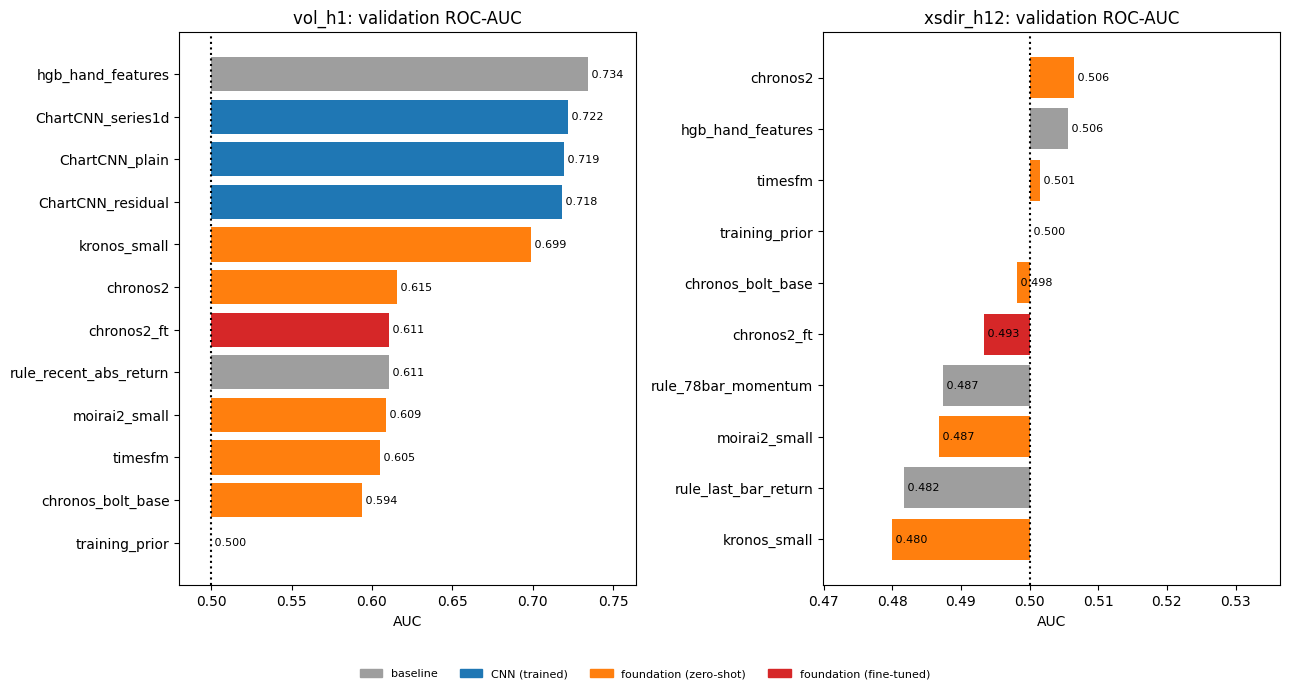

In [ ]:
TABLES = {exp["name"]: scoring.comparison_table(exp["name"], BASE_ROWS, CNN_ROWS, ROWS) for exp in EXPERIMENTS}
for name, table in TABLES.items():
    print(name); display(table.round(4))
    table.to_csv(RUN_LOCAL / f"comparison_{name}.csv")
pd.concat(TABLES, names=["experiment"]).to_csv(RUN_LOCAL / "comparison.csv")
plots.plot_comparison(TABLES, RUN_LOCAL / "comparison.png")

## 9. Save

In [ ]:
archive = shutil.make_archive(str(LOCAL / "results"), "zip", root_dir=RUN_LOCAL)
for f in [archive, RUN_LOCAL / "comparison.csv", RUN_LOCAL / "comparison.png"]:
    shutil.copy2(f, RUN_DRIVE / Path(f).name)
print("saved to", RUN_DRIVE, "| RUN_ID:", RUN_ID)

saved to /content/drive/MyDrive/Colab Notebooks/EC/Project/Demo/Pretrained Model Comparison/runs/run_20261114_012926 | RUN_ID: run_20261114_012926
